In [1]:
import numpy as np

In [4]:
V_itk = 10
d_itk = 5
alpha = 0.5

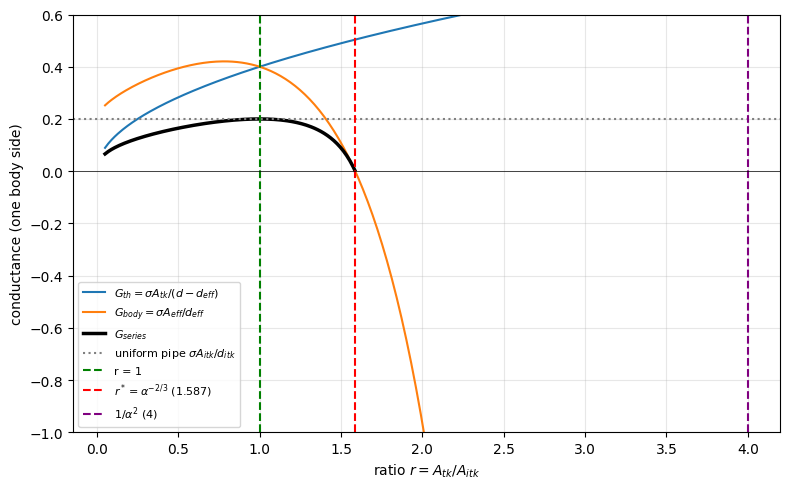

In [9]:
import numpy as np
import matplotlib.pyplot as plt

sigma, alpha = 1.0, 0.5
d_itk, V_itk = 10.0, 20.0              # -> A_itk = 2, so ratio = A_tk / 2
A_itk = V_itk / d_itk

ratios, G_th, G_body, G_series = [], [], [], []
for x in np.linspace(0.1, 8, 400):
    A_tk = x
    ratio = A_tk / A_itk if A_itk > 0 else np.inf

    d_eff_itk = d_itk * (1.0 - alpha * np.sqrt(A_tk / A_itk)) if A_itk > 0 else d_itk
    d_eff_itk = max(d_eff_itk, 1e-9 * d_itk)          # defensive positivity floor

    numerator = A_itk * d_itk - A_tk * (d_itk - d_eff_itk)
    A_eff_itk = numerator / d_eff_itk if d_eff_itk > 0 else A_itk
    V_eff_itk = d_eff_itk * A_eff_itk

    L_th = d_itk - d_eff_itk                          # this side's share of the throat segment
    g_body = sigma * A_eff_itk / d_eff_itk            # G = sigma*A/L
    g_th   = sigma * A_tk / L_th
    g_ser  = 1.0 / (1.0 / g_body + 1.0 / g_th) if g_body > 0 else np.nan   # series; undefined once A_eff <= 0

    ratios.append(ratio); G_body.append(g_body); G_th.append(g_th); G_series.append(g_ser)

ratios = np.array(ratios)
r_star = alpha ** (-2/3)
G_pipe = sigma * A_itk / d_itk

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ratios, G_th, label=r"$G_{th} = \sigma A_{tk}/(d-d_{eff})$")
ax.plot(ratios, G_body, label=r"$G_{body} = \sigma A_{eff}/d_{eff}$")
ax.plot(ratios, G_series, lw=2.5, color="k", label=r"$G_{series}$")
ax.axhline(G_pipe, ls=":", color="gray", label=r"uniform pipe $\sigma A_{itk}/d_{itk}$")
ax.axvline(1.0, ls="--", color="green", label="r = 1")
ax.axvline(r_star, ls="--", color="red", label=rf"$r^* = \alpha^{{-2/3}}$ ({r_star:.3f})")
ax.axvline(1/alpha**2, ls="--", color="purple", label=rf"$1/\alpha^2$ ({1/alpha**2:.0f})")
ax.axhline(0, color="k", lw=0.5)
ax.set_ylim(-1, 3 * G_pipe)
ax.set_xlabel(r"ratio $r = A_{tk}/A_{itk}$"); ax.set_ylabel("conductance (one body side)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()